In [19]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("housing.csv")

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.shape

(20640, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


<Axes: xlabel='median_house_value', ylabel='Count'>

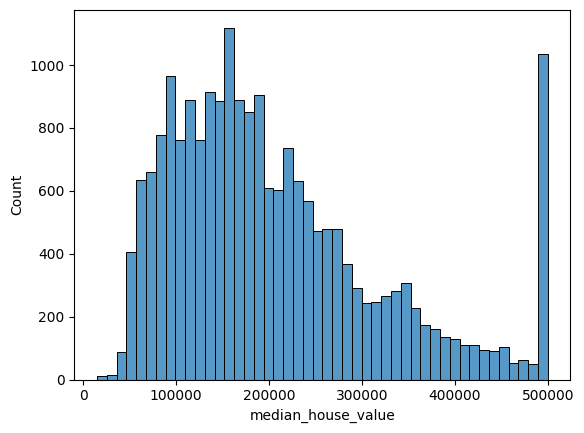

In [7]:
sns.histplot(df['median_house_value'])

<Axes: >

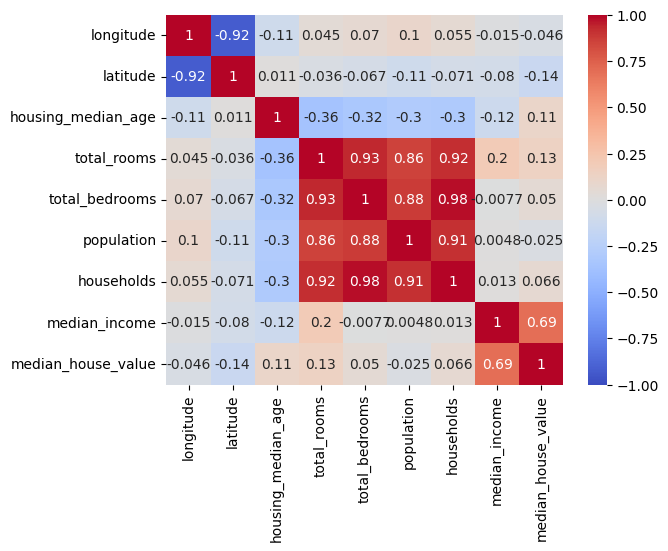

In [9]:
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

<Axes: xlabel='median_income', ylabel='median_house_value'>

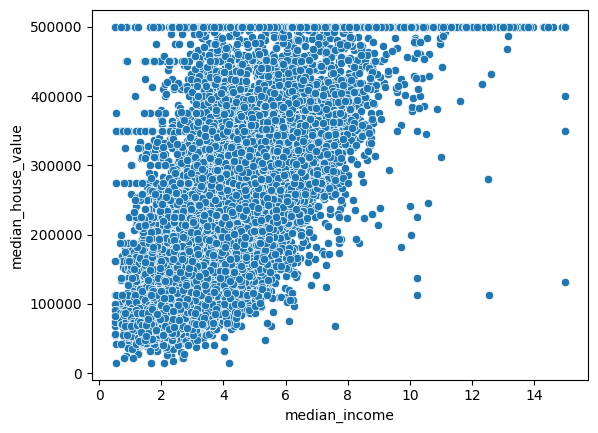

In [11]:
sns.scatterplot(data=df, x="median_income", y="median_house_value")

<Axes: xlabel='longitude', ylabel='median_house_value'>

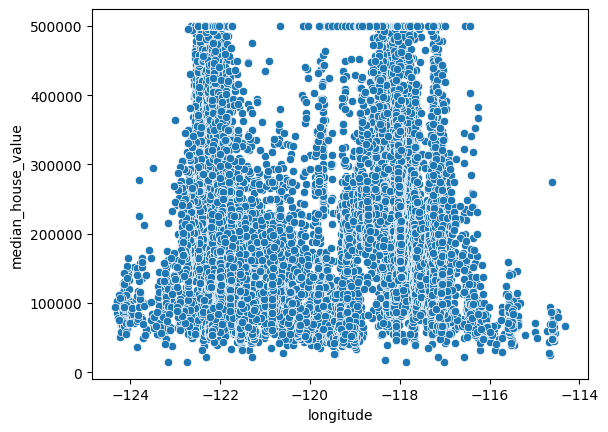

In [12]:
sns.scatterplot(data=df, x="longitude", y="median_house_value")

<Axes: xlabel='ocean_proximity', ylabel='median_house_value'>

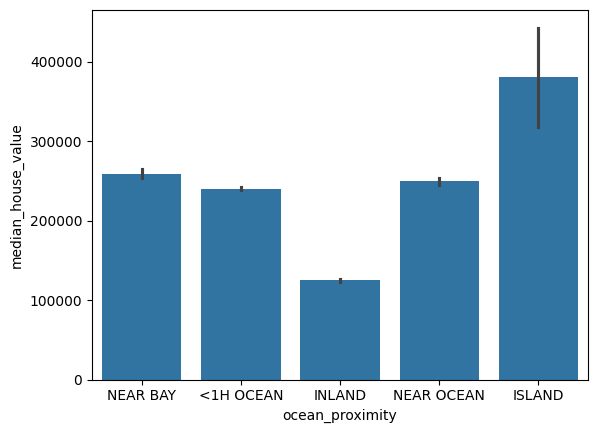

In [13]:
sns.barplot(data=df, x="ocean_proximity", y="median_house_value")

In [14]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [15]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [16]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [17]:
df.duplicated().sum()

0

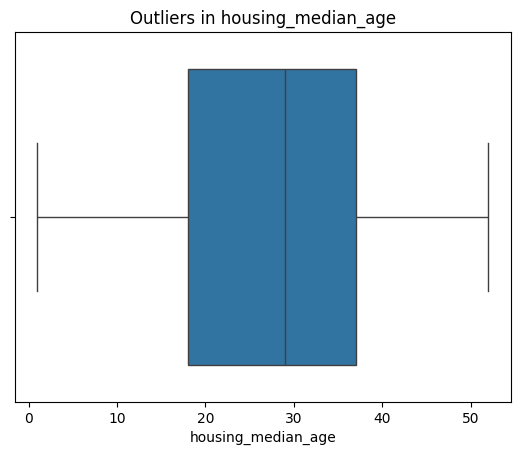

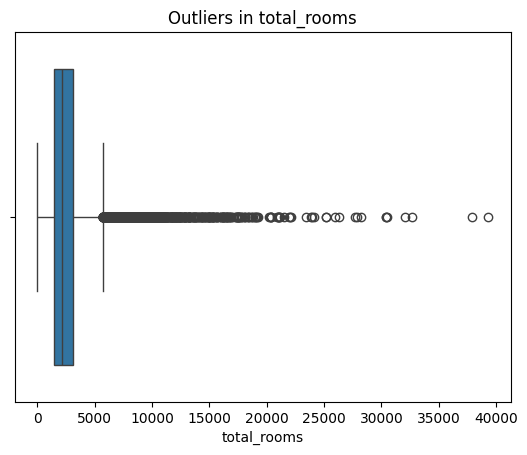

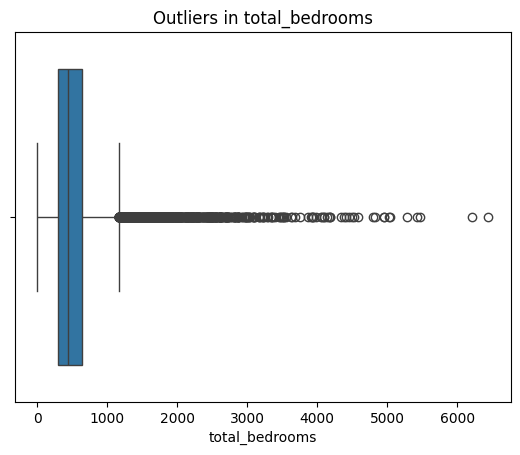

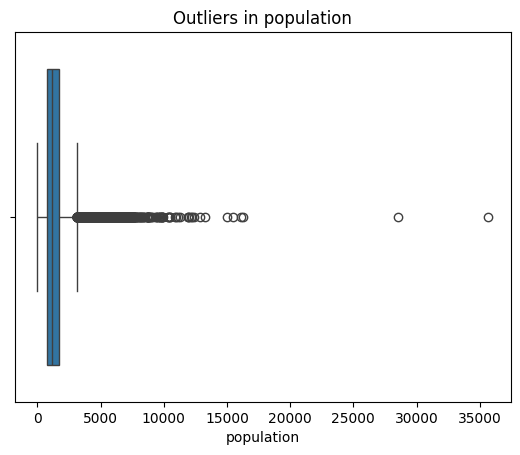

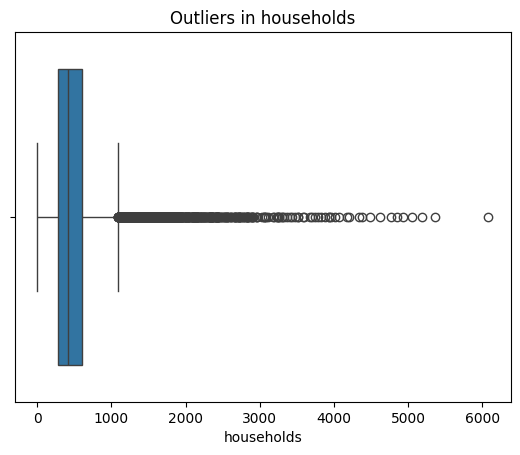

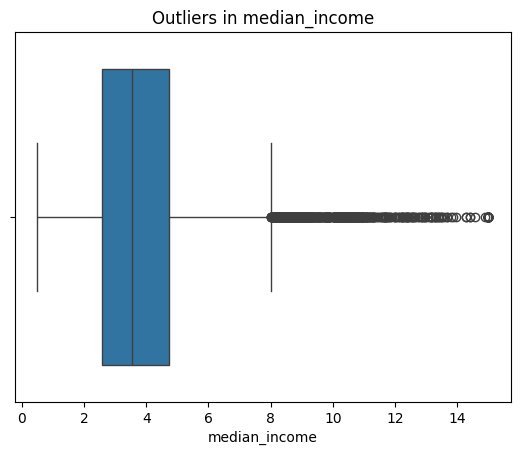

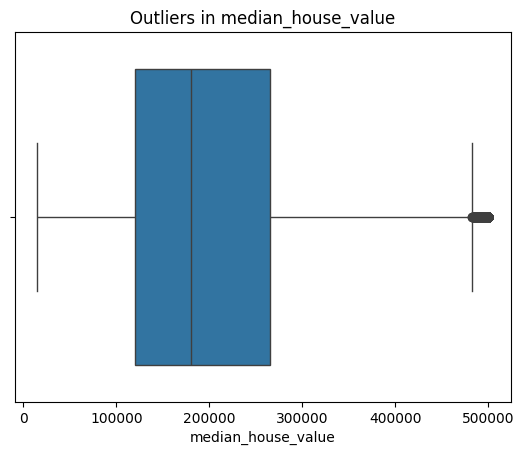

In [20]:
numeric_cols = [
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income',
    'median_house_value'
]

for col in numeric_cols:
    sns.boxplot(data=df, x=col)
    plt.title(f'Outliers in {col}')
    plt.show()

In [21]:
cols = ['total_rooms', 'total_bedrooms', 'households']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df[col] = df[col].clip(lower, upper)

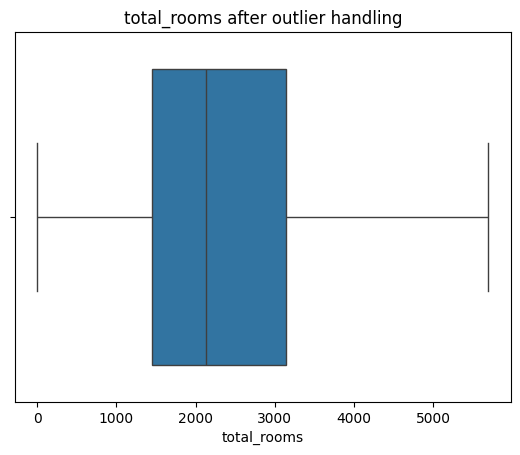

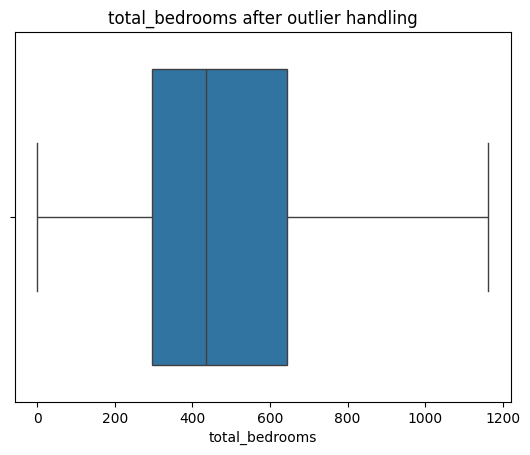

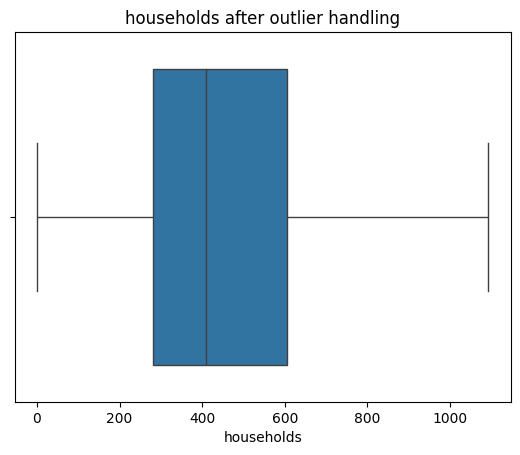

In [22]:
for col in cols:
    sns.boxplot(data=df, x=col)
    plt.title(f'{col} after outlier handling')
    plt.show()

In [23]:
df['rooms_per_household'] = df['total_rooms'] / df['households']

In [24]:
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']

In [25]:
df['population_per_household'] = df['population'] / df['households']

In [26]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.000,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,5698.375,1106.0,2401.0,1092.5,8.3014,358500.0,NEAR BAY,5.215904,0.194090,2.197712
2,-122.24,37.85,52.0,1467.000,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.000,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.000,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [27]:
df = pd.get_dummies(
    df,
    columns=['ocean_proximity'],
    drop_first=True,
    dtype=int
)

In [28]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.000,129.0,322.0,126.0,8.3252,452600.0,6.984127,0.146591,2.555556,0,0,1,0
1,-122.22,37.86,21.0,5698.375,1106.0,2401.0,1092.5,8.3014,358500.0,5.215904,0.194090,2.197712,0,0,1,0
2,-122.24,37.85,52.0,1467.000,190.0,496.0,177.0,7.2574,352100.0,8.288136,0.129516,2.802260,0,0,1,0
3,-122.25,37.85,52.0,1274.000,235.0,558.0,219.0,5.6431,341300.0,5.817352,0.184458,2.547945,0,0,1,0
4,-122.25,37.85,52.0,1627.000,280.0,565.0,259.0,3.8462,342200.0,6.281853,0.172096,2.181467,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.000,374.0,845.0,330.0,1.5603,78100.0,5.045455,0.224625,2.560606,1,0,0,0
20636,-121.21,39.49,18.0,697.000,150.0,356.0,114.0,2.5568,77100.0,6.114035,0.215208,3.122807,1,0,0,0
20637,-121.22,39.43,17.0,2254.000,485.0,1007.0,433.0,1.7000,92300.0,5.205543,0.215173,2.325635,1,0,0,0
20638,-121.32,39.43,18.0,1860.000,409.0,741.0,349.0,1.8672,84700.0,5.329513,0.219892,2.123209,1,0,0,0


In [29]:
X = df.drop("median_house_value",axis=1)
Y = df["median_house_value"]

In [30]:
from sklearn.model_selection import train_test_split
X_train , X_test , Y_train , Y_test = train_test_split( X , Y , train_size = 0.8 , random_state = 42)

In [31]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [32]:
from sklearn.linear_model import LinearRegression , Lasso , Ridge
lr = LinearRegression()
lr.fit(X_train , Y_train)
Y_pred = lr.predict(X_test)

In [35]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


mse = mean_squared_error(Y_test, Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

MSE: 5396675501.417013
RMSE: 73462.06845316169
MAE: 52046.079836329256
R2 Score: 0.5881686106377614


In [36]:
lr.coef_

array([-54967.41155468, -54421.41391614,  14836.38588976,  -9491.79077219,
        37786.60385265, -20350.89234765,  -1018.8703993 ,  81344.00749272,
         6130.71558664,  11852.56931949,  -1184.9395067 , -16060.62471573,
         2023.96161618,   -833.02205136,   1565.25149558])

In [37]:
lr.intercept_

207194.69373788772

In [38]:
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, Y_train)
Y_pred_lasso = lasso_model.predict(X_test)

In [39]:
mae_lasso = mean_absolute_error(Y_test, Y_pred_lasso)
mse_lasso = mean_squared_error(Y_test, Y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(Y_test, Y_pred_lasso)

print("Lasso Regression")
print("MAE:", mae_lasso)
print("MSE:", mse_lasso)
print("RMSE:", rmse_lasso)
print("R2:", r2_lasso)

Lasso Regression
MAE: 52045.86372777134
MSE: 5396647634.448698
RMSE: 73461.87878382024
R2: 0.5881707372233371


In [44]:
lasso_model.coef_

array([-54963.84480869, -54417.86036986,  14836.28794674,  -9488.66606415,
        37777.18510817, -20351.05861121,  -1012.27452305,  81343.48066788,
         6131.13794249,  11853.51835282,  -1184.81770216, -16061.42992786,
         2023.92606955,   -832.65912823,   1565.4244265 ])

In [40]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, Y_train)
Y_pred_ridge = ridge_model.predict(X_test)

In [41]:
mae_ridge = mean_absolute_error(Y_test, Y_pred_ridge)
mse_ridge = mean_squared_error(Y_test, Y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(Y_test, Y_pred_ridge)

print("Ridge Regression")
print("MAE:", mae_ridge)
print("MSE:", mse_ridge)
print("RMSE:", rmse_ridge)
print("R2:", r2_ridge)

Ridge Regression
MAE: 52042.14650976002
MSE: 5396208540.574148
RMSE: 73458.89013982003
R2: 0.5882042453785652


In [45]:
ridge_model.coef_

array([-54849.58826452, -54299.05215639,  14836.95092131,  -9438.10460129,
        37645.04947084, -20349.75137168,   -929.15661131,  81333.20947339,
         6135.02563459,  11866.24328532,  -1184.95530125, -16093.33329727,
         2025.10380797,   -827.82187512,   1572.19214459])

In [47]:
feature_names = [
    'longitude',
    'latitude',
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR_BAY',
    'ocean_proximity_NEAR_OCEAN'
]

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Linear': lr.coef_,
    'Lasso': lasso_model.coef_,
    'Ridge': ridge_model.coef_
})

coefficients

,Feature,Linear,Lasso,Ridge
0,longitude,-54967.411555,-54963.844809,-54849.588265
1,latitude,-54421.413916,-54417.860370,-54299.052156
2,housing_median_age,14836.385890,14836.287947,14836.950921
3,total_rooms,-9491.790772,-9488.666064,-9438.104601
4,total_bedrooms,37786.603853,37777.185108,37645.049471
5,population,-20350.892348,-20351.058611,-20349.751372
6,households,-1018.870399,-1012.274523,-929.156611
7,median_income,81344.007493,81343.480668,81333.209473
8,rooms_per_household,6130.715587,6131.137942,6135.025635
9,bedrooms_per_room,11852.569319,11853.518353,11866.243285
